# Local Photometry: Apertures, PSF and Upper Limits

This example shows the local photometry at the position of SN 2009ig, in its host NGC 1015, with images of very different resolution (PanSTARRS, 2MASS and WISE): apertures in physical and angular units, the PSF size of each image, the upper limits for non-detections, the quality flags, and the PSF matching of images of different resolution (to unWISE W1).

In [1]:
import hostphot
print('HostPhot version:', hostphot.__version__)

HostPhot version: 4.0.0


In [2]:
import pandas as pd
from hostphot.utils import plot_image
from hostphot.cutouts import download_images
from hostphot.processing import coadd_images, create_mask
from hostphot.photometry import local_photometry as lp
from hostphot.surveys_utils import get_survey_filters

name = 'SN2009ig'
ra, dec = 39.548375, -1.312556  # SN
host_ra, host_dec = 39.5482, -1.3187  # NGC 1015
z = 0.0088

surveys = ['PanSTARRS', '2MASS', 'WISE']
for survey in surveys:
    download_images(name, host_ra, host_dec, survey=survey, size=7, overwrite=False)

## Masking

The local photometry can also use masked images (`use_mask=True`, the default), so that foreground stars or neighbouring galaxies do not contaminate the apertures. As in the global photometry example, the mask is measured on a PanSTARRS coadd, with a model of the host galaxy (only the stars and the sources much brighter than the host are masked), and applied to all the images:

In [3]:
coadd_images(name, filters='riz', survey='PanSTARRS')
create_mask(name, host_ra, host_dec, filt='riz', survey='PanSTARRS', method='host_model',
            crossmatch=True, save_mask_params=True)

for survey in surveys:
    for filt in get_survey_filters(survey):
        create_mask(name, host_ra, host_dec, filt=filt, survey=survey,
                    ref_filt='riz', ref_survey='PanSTARRS', save_input=False)

/home/tomas/Softwares/hostphot/src/hostphot/processing/background.py:340: UserWarning: WISE W1: 96% of the image (with data) is masked for the background estimation (e.g. the galaxy fills most of the image), so the background (and the photometry of large apertures) might be unreliable.
  warnings.warn(msg)
/home/tomas/Softwares/hostphot/src/hostphot/processing/background.py:340: UserWarning: WISE W2: 88% of the image (with data) is masked for the background estimation (e.g. the galaxy fills most of the image), so the background (and the photometry of large apertures) might be unreliable.
  warnings.warn(msg)


## Apertures in kpc and arcsec

By default, the aperture radii are in kpc (`ap_units="kpc"`), converted into an angular size with the redshift and a flat ΛCDM cosmology (`H0=70`, `Om0=0.3`; it can be changed with `lp.choose_cosmology()`):

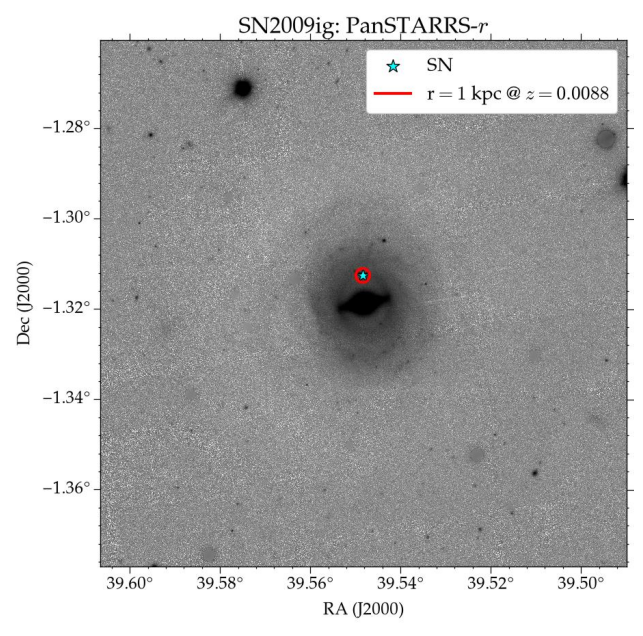

In [4]:
ps = lp.multi_band_phot(name, ra, dec, z, survey='PanSTARRS', ap_radii=[1, 2, 4], save_plots=True)
plot_image(f'images/{name}/PanSTARRS/local_PanSTARRS_r_1kpc.jpg')

The columns are named after the filter and the aperture radius (e.g. `r_1`, `r_1_err` for 1 kpc), with the same outputs as the global photometry: AB magnitudes, flux densities in µJy, 3-sigma upper limits and the quality flags. The PSF FWHM of each image (`{filt}_psf_fwhm`, in arcsec) is also given:

In [5]:
def summary(df, filters, radii):
    rows = []
    for filt in filters:
        for radius in radii:
            col = f'{filt}_{radius}'
            if col not in df.columns:
                continue
            flags = [flag for flag in ['bkg', 'coverage', 'psf', 'err'] if df[f'{col}_{flag}_flag'].iloc[0]]
            rows.append([filt, radius, df[col].iloc[0], df[f'{col}_err'].iloc[0], df[f'{col}_AB'].iloc[0],
                         df[f'{col}_flux_uJy'].iloc[0], df[f'{col}_AB_ulim'].iloc[0],
                         df[f'{filt}_psf_fwhm'].iloc[0], ', '.join(flags)])
    return pd.DataFrame(rows, columns=['filter', 'radius', 'mag', 'mag_err', 'AB', 'flux_uJy', 'AB_ulim',
                                       'psf_fwhm', 'flags'])

summary(ps, 'grizy', [1, 2, 4]).round(3)

,filter,radius,mag,mag_err,AB,flux_uJy,AB_ulim,psf_fwhm,flags
0,g,1,18.043,0.041,18.043,220.284,20.416,1.31,
1,g,2,16.536,0.030,16.536,882.347,19.232,1.31,
2,g,4,14.216,0.017,14.216,7475.398,17.518,1.31,
3,r,1,17.339,0.026,17.339,421.091,20.210,1.19,
4,r,2,15.828,0.026,15.828,1693.547,18.675,1.19,
5,r,4,13.475,0.018,13.475,14786.117,16.737,1.19,
6,i,1,17.015,0.025,17.015,567.440,19.928,1.11,
7,i,2,15.511,0.026,15.511,2268.512,18.364,1.11,
8,i,4,13.127,0.020,13.127,20385.991,16.297,1.11,
9,z,1,16.894,0.033,16.894,634.538,19.479,1.07,


At $z=0.0088$, 1 kpc corresponds to ~5.5 arcsec. The radii can also be given in arcsec with `ap_units="arcsec"`, e.g. to use the same angular aperture for objects at different redshifts:

In [6]:
ps_arcsec = lp.multi_band_phot(name, ra, dec, z, survey='PanSTARRS', ap_radii=[3, 6], ap_units='arcsec',
                               save_plots=False, save_results=False)
summary(ps_arcsec, 'gri', [3, 6]).round(3)

,filter,radius,mag,mag_err,AB,flux_uJy,AB_ulim,psf_fwhm,flags
0,g,3,19.326,0.056,19.326,67.539,21.360,1.31,
1,g,6,17.869,0.037,17.869,258.423,20.338,1.31,
2,r,3,18.641,0.028,18.641,126.980,21.421,1.19,
3,r,6,17.166,0.025,17.166,493.854,20.072,1.19,
4,i,3,18.318,0.027,18.318,170.993,21.141,1.11,
5,i,6,16.847,0.023,16.847,662.592,19.838,1.11,


## PSF and resolution

The flux within a small aperture depends on the resolution of the image: for apertures smaller than the PSF, part of the flux of the region is spread outside the aperture, while the light of the surroundings is spread into it. HostPhot gives a warning and sets the `psf` flag when the aperture radius is smaller than the PSF FWHM, which happens for WISE (6-12 arcsec) with a 1-kpc aperture:

In [7]:
wise = lp.multi_band_phot(name, ra, dec, z, survey='WISE', ap_radii=[1, 4], save_plots=True)

/home/tomas/Softwares/hostphot/src/hostphot/processing/background.py:340: UserWarning: WISE W1: 97% of the image (with data) is masked for the background estimation (e.g. the galaxy fills most of the image), so the background (and the photometry of large apertures) might be unreliable.
  warnings.warn(msg)


/home/tomas/Softwares/hostphot/src/hostphot/photometry/local_photometry.py:357: PSFWarning: WISE W1: the aperture radius (5.53 arcsec) is smaller than the PSF FWHM (8.9 arcsec), so the flux depends strongly on the resolution; compare it with other surveys with care or use a larger aperture.
  warnings.warn(


/home/tomas/Softwares/hostphot/src/hostphot/photometry/photometry_utils.py:1607: ErrorFloorWarning: The blank-aperture noise floor could not be estimated for a 16.1-pixel aperture (not enough blank sky in the image), so the uncertainty might be underestimated. Consider downloading a larger image.
  warnings.warn(


/home/tomas/Softwares/hostphot/src/hostphot/photometry/local_photometry.py:357: PSFWarning: WISE W2: the aperture radius (5.53 arcsec) is smaller than the PSF FWHM (10 arcsec), so the flux depends strongly on the resolution; compare it with other surveys with care or use a larger aperture.
  warnings.warn(


/home/tomas/Softwares/hostphot/src/hostphot/photometry/local_photometry.py:357: PSFWarning: WISE W3: the aperture radius (5.53 arcsec) is smaller than the PSF FWHM (13.3 arcsec), so the flux depends strongly on the resolution; compare it with other surveys with care or use a larger aperture.
  warnings.warn(


/home/tomas/Softwares/hostphot/src/hostphot/photometry/local_photometry.py:357: PSFWarning: WISE W4: the aperture radius (5.53 arcsec) is smaller than the PSF FWHM (24 arcsec), so the flux depends strongly on the resolution; compare it with other surveys with care or use a larger aperture.
  warnings.warn(
/home/tomas/Softwares/hostphot/src/hostphot/processing/background.py:456: BackgroundWarning: WISE W4 (5.53 arcsec aperture): the background subtracted inside the aperture differs from the sky level around it by 1591% of the flux, so the background probably follows the outskirts of the galaxy (e.g. a galaxy filling most of the image) and the flux is unreliable. Consider downloading a larger image, or using bkg_sub=False if the image is already background subtracted.
  warnings.warn(
/home/tomas/Softwares/hostphot/src/hostphot/photometry/photometry_utils.py:651: UserWarning: WISE W4: the flux is negative or zero (not detected), so the magnitude is NaN; the flux and its uncertainty are 

/home/tomas/Softwares/hostphot/src/hostphot/photometry/local_photometry.py:357: PSFWarning: WISE W4: the aperture radius (22.1 arcsec) is smaller than the PSF FWHM (24 arcsec), so the flux depends strongly on the resolution; compare it with other surveys with care or use a larger aperture.
  warnings.warn(
/home/tomas/Softwares/hostphot/src/hostphot/processing/background.py:456: BackgroundWarning: WISE W4 (22.1 arcsec aperture): the background subtracted inside the aperture differs from the sky level around it by 74% of the flux, so the background probably follows the outskirts of the galaxy (e.g. a galaxy filling most of the image) and the flux is unreliable. Consider downloading a larger image, or using bkg_sub=False if the image is already background subtracted.
  warnings.warn(


In [8]:
summary(wise, ['W1', 'W2', 'W3', 'W4'], [1, 4]).round(3)

,filter,radius,mag,mag_err,AB,flux_uJy,AB_ulim,psf_fwhm,flags
0,W1,1,14.321,0.024,17.020,564.825,19.973,8.9,psf
1,W1,4,10.608,0.007,13.307,17270.333,17.546,8.9,err
2,W2,1,14.309,0.042,17.648,316.930,19.998,10.0,psf
3,W2,4,10.595,0.010,13.934,9692.018,17.878,10.0,
4,W3,1,12.547,0.136,17.721,296.130,18.785,13.3,psf
5,W3,4,9.293,0.047,14.467,5933.506,16.683,13.3,
6,W4,1,NaN,NaN,NaN,-6.758,17.806,24.0,"bkg, psf"
7,W4,4,9.444,0.813,16.064,1362.144,15.186,24.0,"bkg, psf"


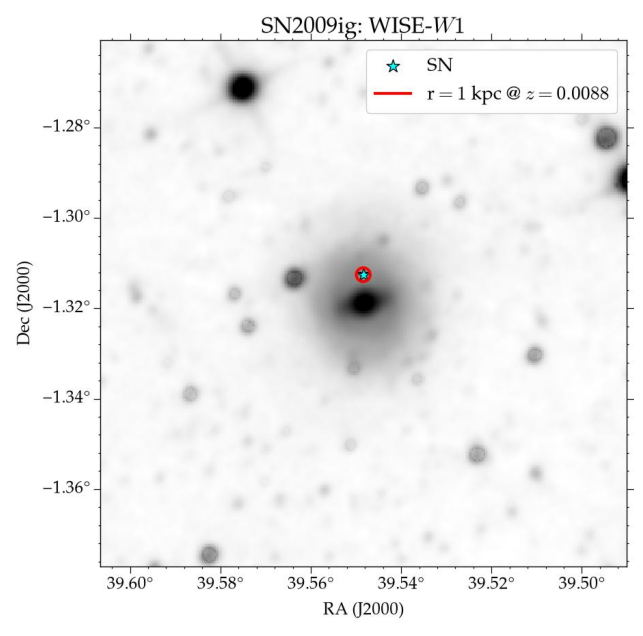

In [9]:
plot_image(f'images/{name}/WISE/local_WISE_W1_1kpc.jpg')

In W4, the SN region is not detected in the 1-kpc aperture: the flux is negative, so the magnitude is NaN, while the flux and its uncertainty are kept and the 3-sigma upper limit (`AB_ulim`) can be used instead. The `bkg` flag also marks the W4 apertures where the background follows the outskirts of the galaxy (the galaxy fills most of the low-resolution image), so their fluxes are not reliable.

## SED

The SED of the local photometry is plotted for a given aperture radius (upper limits for the non-detections):

In [10]:
_ = lp.multi_band_phot(name, ra, dec, z, survey='2MASS', ap_radii=[1, 4], save_plots=False)

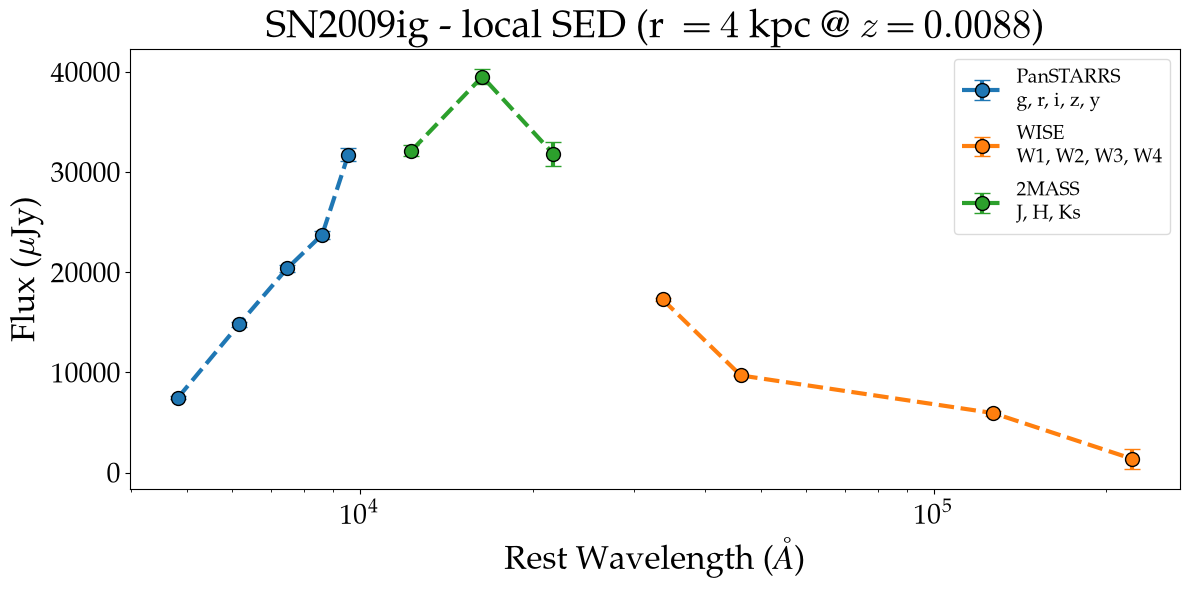

In [11]:
from hostphot.photometry.sed_plotting import plot_sed

plot_sed(name, phot_type='local', z=z, radius=4, plot_flux=True)

## PSF matching

The colours of small apertures measured in images of different resolution are biased, as the fraction of the light of the region kept in the aperture (and the light of the surroundings spread into it) depends on the PSF. With `psf_match`, the images are convolved to a common, broader PSF before the photometry. The target can be a FWHM in arcsec (Gaussian kernel), `(survey, filter)` of an image of the object, or `"broadest"` (the broadest PSF among the filters of the photometry). The PSF FWHM of each image is taken from its header or measured from its Gaia stars (the typical value of the filter is used otherwise, with the `psf_match` flag). For unWISE W1 and W2 targets, the kernel reproduces the unWISE PSF model, with its strong wings.

Here, the PanSTARRS, 2MASS and unWISE images are matched to unWISE W1. The results are not saved (`save_results=False`), so that the photometry above (and its SED) is kept:

In [12]:
download_images(name, host_ra, host_dec, survey='unWISE', size=7, filters=['W1', 'W2'], overwrite=False)
for filt in ['W1', 'W2']:
    create_mask(name, host_ra, host_dec, filt=filt, survey='unWISE',
                ref_filt='riz', ref_survey='PanSTARRS', save_input=False)

radii = [1, 2]
sets = {'PanSTARRS': list('grizy'), '2MASS': ['J', 'H', 'Ks'], 'unWISE': ['W1', 'W2']}
native, matched = {}, {}
for survey, filters in sets.items():
    kwargs = dict(survey=survey, filters=filters, ap_radii=radii, save_plots=False, save_results=False)
    native[survey] = lp.multi_band_phot(name, ra, dec, z, **kwargs)
    matched[survey] = lp.multi_band_phot(name, ra, dec, z, psf_match=('unWISE', 'W1'), **kwargs)

print(f"target FWHM: {matched['PanSTARRS']['psf_match_fwhm'].iloc[0]:.2f} arcsec")

/home/tomas/Softwares/hostphot/src/hostphot/photometry/psf_matching.py:400: UserWarning: PanSTARRS g: with a target PSF of 5.88 arcsec, the light of faint and neighbouring sources spread by the PSF contributes to the aperture (confusion), especially in deep or crowded images; it is only partly included in the uncertainty.
  warnings.warn(


/home/tomas/Softwares/hostphot/src/hostphot/photometry/local_photometry.py:357: PSFWarning: PanSTARRS g: the aperture radius (5.53 arcsec) is smaller than the PSF FWHM (5.88 arcsec), so the flux depends strongly on the resolution; compare it with other surveys with care or use a larger aperture.
  warnings.warn(


/home/tomas/Softwares/hostphot/src/hostphot/photometry/psf_matching.py:400: UserWarning: PanSTARRS r: with a target PSF of 5.88 arcsec, the light of faint and neighbouring sources spread by the PSF contributes to the aperture (confusion), especially in deep or crowded images; it is only partly included in the uncertainty.
  warnings.warn(


/home/tomas/Softwares/hostphot/src/hostphot/photometry/local_photometry.py:357: PSFWarning: PanSTARRS r: the aperture radius (5.53 arcsec) is smaller than the PSF FWHM (5.88 arcsec), so the flux depends strongly on the resolution; compare it with other surveys with care or use a larger aperture.
  warnings.warn(


/home/tomas/Softwares/hostphot/src/hostphot/photometry/psf_matching.py:400: UserWarning: PanSTARRS i: with a target PSF of 5.88 arcsec, the light of faint and neighbouring sources spread by the PSF contributes to the aperture (confusion), especially in deep or crowded images; it is only partly included in the uncertainty.
  warnings.warn(


/home/tomas/Softwares/hostphot/src/hostphot/photometry/local_photometry.py:357: PSFWarning: PanSTARRS i: the aperture radius (5.53 arcsec) is smaller than the PSF FWHM (5.88 arcsec), so the flux depends strongly on the resolution; compare it with other surveys with care or use a larger aperture.
  warnings.warn(


... (5 outputs left out)

/home/tomas/Softwares/hostphot/src/hostphot/photometry/psf_matching.py:400: UserWarning: 2MASS H: with a target PSF of 5.88 arcsec, the light of faint and neighbouring sources spread by the PSF contributes to the aperture (confusion), especially in deep or crowded images; it is only partly included in the uncertainty.
  warnings.warn(
/home/tomas/Softwares/hostphot/src/hostphot/photometry/local_photometry.py:357: PSFWarning: 2MASS H: the aperture radius (5.53 arcsec) is smaller than the PSF FWHM (5.88 arcsec), so the flux depends strongly on the resolution; compare it with other surveys with care or use a larger aperture.
  warnings.warn(


/home/tomas/Softwares/hostphot/src/hostphot/photometry/psf_matching.py:400: UserWarning: 2MASS Ks: with a target PSF of 5.88 arcsec, the light of faint and neighbouring sources spread by the PSF contributes to the aperture (confusion), especially in deep or crowded images; it is only partly included in the uncertainty.
  warnings.warn(
/home/tomas/Softwares/hostphot/src/hostphot/photometry/local_photometry.py:357: PSFWarning: 2MASS Ks: the aperture radius (5.53 arcsec) is smaller than the PSF FWHM (5.88 arcsec), so the flux depends strongly on the resolution; compare it with other surveys with care or use a larger aperture.
  warnings.warn(
/home/tomas/Softwares/hostphot/src/hostphot/photometry/local_photometry.py:357: PSFWarning: unWISE W1: the aperture radius (5.53 arcsec) is smaller than the PSF FWHM (6.1 arcsec), so the flux depends strongly on the resolution; compare it with other surveys with care or use a larger aperture.
  warnings.warn(
/home/tomas/Softwares/hostphot/src/hostp

target FWHM: 5.88 arcsec


/home/tomas/Softwares/hostphot/src/hostphot/photometry/psf_matching.py:384: PSFMatchWarning: unWISE W2: the PSF of the image (FWHM 6.44 arcsec) is not narrower than the target of the PSF matching (5.88 arcsec), so the image is not matched.
  warnings.warn(
/home/tomas/Softwares/hostphot/src/hostphot/photometry/local_photometry.py:357: PSFWarning: unWISE W2: the aperture radius (5.53 arcsec) is smaller than the PSF FWHM (6.44 arcsec), so the flux depends strongly on the resolution; compare it with other surveys with care or use a larger aperture.
  warnings.warn(


The PSF FWHM of the matched photometry (`{filt}_psf_fwhm`) is that of the target, and `psf_match_fwhm` gives the target FWHM (measured from the stars of the unWISE W1 image). The fluxes in the 1-kpc (5.5 arcsec) and 2-kpc apertures, and the ratios of the matched to the native fluxes and uncertainties:

In [13]:
rows = []
for survey, filters in sets.items():
    nat, mat = native[survey], matched[survey]
    for filt in filters:
        row = [survey, filt, nat[f'{filt}_psf_fwhm'].iloc[0], mat[f'{filt}_psf_fwhm'].iloc[0],
               mat[f'{filt}_psf_match_flag'].iloc[0]]
        for r in radii:
            flux, flux_matched = nat[f'{filt}_{r}_flux_uJy'].iloc[0], mat[f'{filt}_{r}_flux_uJy'].iloc[0]
            row += [flux, flux_matched / flux,
                    mat[f'{filt}_{r}_flux_uJy_err'].iloc[0] / nat[f'{filt}_{r}_flux_uJy_err'].iloc[0]]
        rows.append(row)
columns = ['survey', 'filter', 'psf_fwhm', 'psf_fwhm_matched', 'psf_match_flag']
columns += [f'{c}_{r}kpc' for r in radii for c in ['flux', 'flux_ratio', 'err_ratio']]
pd.DataFrame(rows, columns=columns).round(2)

,survey,filter,psf_fwhm,psf_fwhm_matched,psf_match_flag,flux_1kpc,flux_ratio_1kpc,err_ratio_1kpc,flux_2kpc,flux_ratio_2kpc,err_ratio_2kpc
0,PanSTARRS,g,1.31,5.88,False,220.28,1.08,0.96,882.35,1.13,1.14
1,PanSTARRS,r,1.19,5.88,False,421.09,1.09,1.06,1693.55,1.13,1.01
2,PanSTARRS,i,1.11,5.88,False,567.44,1.08,0.97,2268.51,1.14,1.09
3,PanSTARRS,z,1.07,5.88,False,634.54,1.09,0.99,2511.48,1.16,1.15
4,PanSTARRS,y,1.02,5.88,False,879.41,1.09,0.88,3604.37,1.13,1.07
5,2MASS,J,2.50,5.88,False,691.35,1.26,0.68,2979.35,1.27,0.93
6,2MASS,H,2.50,5.88,False,930.67,1.25,0.94,3623.40,1.35,0.88
7,2MASS,Ks,2.50,5.88,False,340.24,1.79,0.74,3060.18,1.15,0.83
8,unWISE,W1,6.10,5.88,False,568.24,1.00,1.00,2333.34,1.00,1.00
9,unWISE,W2,6.40,6.44,True,308.58,1.00,1.00,1347.22,1.00,1.00


The SN lies ~20 arcsec from the nucleus of NGC 1015, so the matching spreads the light of the bright centre of the galaxy into the apertures: the fluxes of the sharper images increase, more for 2MASS (the near-infrared light is more concentrated in the bulge) than for PanSTARRS, as they now include the same light as the unWISE apertures. Note that unWISE W2 is not matched: its PSF is slightly broader than that of W1, so it cannot be matched to it (it is flagged with `psf_match`; `psf_match=('unWISE', 'W2')` or `"broadest"` could be used instead).

The uncertainties of the matched images include the noise correlated by the convolution (from blank apertures in the matched image), so they do not decrease although the images are smoother. The local SED in the 1-kpc aperture, with and without the matching:

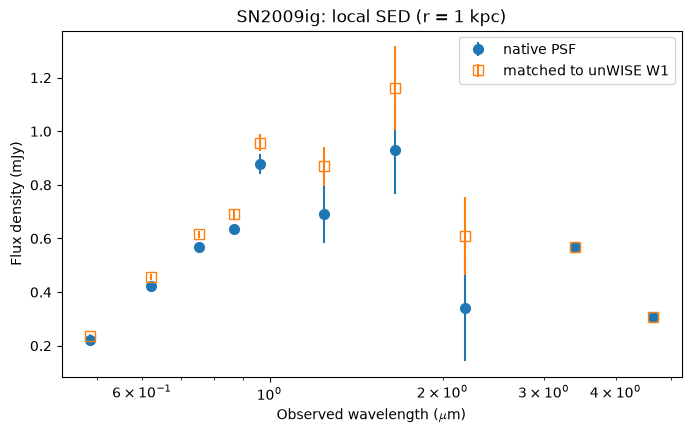

In [14]:
import matplotlib.pyplot as plt
from hostphot.photometry.sed_plotting import get_eff_wave

fig, ax = plt.subplots(figsize=(8, 4.5))
for results, label, marker in [(native, 'native PSF', 'o'), (matched, 'matched to unWISE W1', 's')]:
    waves, fluxes, errors = [], [], []
    for survey, filters in sets.items():
        for filt in filters:
            waves.append(get_eff_wave(filt, survey) / 1e4)
            fluxes.append(results[survey][f'{filt}_1_flux_uJy'].iloc[0] / 1e3)
            errors.append(results[survey][f'{filt}_1_flux_uJy_err'].iloc[0] / 1e3)
    ax.errorbar(waves, fluxes, errors, fmt=marker, ms=7, mfc='none' if marker == 's' else None, label=label)
ax.set_xscale('log')
ax.set_xlabel(r'Observed wavelength ($\mu$m)')
ax.set_ylabel('Flux density (mJy)')
ax.set_title(f'{name}: local SED (r = 1 kpc)')
ax.legend()
plt.show()

The matching makes the colours consistent, but at the resolution of the target: the matched photometry describes a larger region than the aperture, and with a target of ~6 arcsec, faint and neighbouring sources spread by the PSF also contribute (confusion; HostPhot warns about it). See [PSF matching](../further_information/photometry.rst#psf-matching) for the details and limitations.